### init

In [4]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "0"
os.environ["XLA_PYTHON_CLIENT_PREALLOCATE"] = "false"
os.environ["XLA_PYTHON_CLIENT_MEM_FRACTION"] = ".99"
import jax
import jax.numpy as jnp
from src.qwen_jax import QwenTextClassificationWrapper
import numpy as np
from flax.core import freeze, unfreeze
from qwen_fineTuning_PtoC_fixCps import Config, _setup_training_env, _prepare_datasets
from qwen_fineTuning_PtoC_fixCps import _compute_posterior_weights, post_pred_performance
from matplotlib import pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np


%load_ext autoreload
%autoreload 2




The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


### Subspace model test

In [ ]:
# setup all
config = Config(data={
        'dataset_path': "artifacts/winogrande_m_dataset:v0/",
        'val_percentage': 0.1,
    })
config.net_kwargs['model_path'] = "artifacts/qwen2.5_7B_bfloat16:v0"
rng_key = jax.random.PRNGKey(0)
data, unique_target_ids, rng_key = _prepare_datasets(
        rng_key,
        dataset_path=config.data['dataset_path'],
        val_percentage=config.data.get('val_percentage', 0.0),
        batch_size=config.train_hyper.batch_size,
        smoke_test=config.train_hyper.smoke_test,
        logger=False)
config.net_kwargs['target_token_ids'] = unique_target_ids
env, params, rng_key = _setup_training_env(config, data, rng_key)
env

Dataset loaded: 2500 samples, 2 classes
Target token IDs: [[32]
 [33]]
Validation data are used
Training data: 2248 samples, Validation data: 252 samples
save best parameters


TrainingEnv(s_model=<src.subspace_curve.LoRACategorySubspace object at 0x7f9230581870>, optimizer=GradientTransformationExtraArgs(init=<function chain.<locals>.init_fn at 0x7f9230125360>, update=<function chain.<locals>.update_fn at 0x7f92301253f0>), t_sample_fn=<function _setup_t_sample_fn.<locals>.t_sample_fn_v2 at 0x7f9230576c20>, rho_scheduler=<function _setup_rho_scheduler.<locals>.<lambda> at 0x7f9230577250>, valid_metrics_fn=<function _setup_validation.<locals>.valid_metrics_fn at 0x7f9230124ca0>, empty_metric=({'val_mean_loss': Array(inf, dtype=float32), 'val_mean_acc': Array(-inf, dtype=float32), 'val_mean_ece': Array(inf, dtype=float32), 'val_bma_ll': Array(-inf, dtype=float32), 'val_bma_acc': Array(-inf, dtype=float32), 'val_bma_ece': Array(inf, dtype=float32)}, None), get_best_params=<function _setup_validation.<locals>.get_best_params at 0x7f9230124d30>, train_step=<PjitFunction of <function _setup_training_env.<locals>._scan_jit at 0x7f9230125870>>)

In [5]:
config.data

{'dataset_path': 'artifacts/winogrande_m_dataset:v0/', 'val_percentage': 0.1}

In [11]:
from jax import random
from qwen_fineTuning_PtoC_fixCps import _pad_to_batch, post_pred_performance, ece_fn
from functools import partial

def setup_metrics(model, batch_size, x, attention_mask, target, n_samples, use_linspace=False, average=True, key_prefix='', num_bins_ece=15, t_sample_fn=None, t_max=None, scan_data_loop=True):
    if t_max is None:
        t_max = getattr(model, 't_max', 1.0)

    # Fix 2: pad to full batches once at setup time — eliminates the
    # ``if len(idx_last) > 0`` Python branch inside acc_fn, which used to
    # produce arrays of different shapes and trigger JAX recompilation.
    x_pad, attn_pad, target_pad, n_valid = _pad_to_batch(x, attention_mask, target, batch_size)
    idx_ = jnp.arange(x_pad.shape[0]).reshape(-1, batch_size)  # always full batches

    # Build the t-sampling closure (n_s passed explicitly so get_t is shape-generic).
    if t_sample_fn is None:
        if use_linspace:
            def get_t_v1(key, n_s):
                # Return n_s evenly spaced samples in [0, t_max], excluding t_max itself.
                return jnp.linspace(0, t_max, n_s, endpoint=False)
            get_t = get_t_v1
        else:
            def get_t_v2(key, n_s):
                # Return n_s random samples in [0, t_max).
                return random.uniform(key, (n_s,), minval=0., maxval=t_max)
            get_t = get_t_v2
    else:
        if use_linspace:
            raise ValueError("Cannot use linspace sampling with custom t_sample_fn")
        def get_t_v3(key, n_s):
            return jax.vmap(lambda key: t_sample_fn(key))(random.split(key, n_s))
        get_t = get_t_v3

    # Fix 1 & 3: a single jitted evaluation core whose trace is stable as long
    # as the closed-over arrays (x_pad, attn_pad, target_pad) keep the same
    # shape.  ``n_s`` is declared static so JAX never conflates a 3-sample
    # smoke-test trace with the 20-sample full-eval trace.
    # @partial(jax.jit, static_argnames=('n_s',))
    def _eval_core(rng_key, params, n_s):
        def pred(rng_key, data_idx, _n_s=n_s):
            x_batch = x_pad.at[data_idx].get()
            att_m_batch = attn_pad.at[data_idx].get()
            # y_batch = target_pad.at[data_idx].get()

            rng_key, key_ = random.split(rng_key)
            t_tree = get_t(key_, _n_s)  # shape (n_s,)

            def single_pred(carry, t):
                key, x_b, att_b = carry
                key, subkey = random.split(key)
                out, _ = model(params['params'], {}, t, (x_b, att_b), train=False, key=subkey)
                return (key, x_b, att_b), out  # out shape (batch_size, output_dim)

            (rng_key, _, _), out = jax.lax.scan(single_pred, (rng_key, x_batch, att_m_batch), t_tree)
            return rng_key, out  # out shape (n_s, batch_size, output_dim)

        if scan_data_loop:
            # out: (n_batches, n_s, batch_size, output_dim)
            rng_key, out = jax.lax.scan(pred, rng_key, idx_)
        else:
            # jit_pred_fn = jax.jit(pred)
            out = []
            for data_idx in idx_:
                rng_key, out_batch = pred(rng_key, data_idx)  # (n_s, batch_size, output_dim)
                out.append(out_batch)
            out = jnp.stack(out, axis=0)  # (n_batches, n_s, batch_size, output_dim)
        # -> (n_s, n_padded, output_dim)  — trim padding
        out = out.transpose(1, 0, 2, 3).reshape(n_s, -1, out.shape[-1])[:, :n_valid, :]
        return rng_key, out  # (n_s, n_valid, output_dim)

    # Use shared post_pred_performance from src.utils (returns prefixed keys when key_prefix provided)

    def acc_fn(rng_key, params):
        rng_key, out = _eval_core(rng_key, params, n_samples)
        # out: (n_samples, n_valid, output_dim)

        bma_metrics = post_pred_performance(out, target, key_prefix=key_prefix + "bma_", num_bins=num_bins_ece)

        ece = jax.vmap(ece_fn, in_axes=(0, None, None))(out, target, num_bins_ece)  # (n_samples,)
        acc = jnp.argmax(out, axis=-1) == target  # (n_samples, n_valid)

        # Recompute NLL from returned logits — avoids accumulating a separate
        # loss tensor through the padded scan, eliminating shape mismatches.
        log_probs = jax.nn.log_softmax(out, axis=-1)  # (n_samples, n_valid, n_classes)
        loss = -jnp.sum(log_probs * jax.nn.one_hot(target, out.shape[-1]), axis=-1)  # (n_samples, n_valid)

        if average:
            ece = jnp.mean(ece)
            loss = loss.mean()
            acc = acc.sum() / (n_samples * n_valid)
        else:
            loss = jnp.mean(loss, axis=1)   # (n_samples,) — mean NLL per t-sample
            acc = jnp.sum(acc, axis=1) / n_valid

        return {key_prefix + 'loss': loss, key_prefix + 'acc': acc, key_prefix + 'ece': ece, **bma_metrics}, out
    return acc_fn

In [21]:
pred_fn = setup_metrics(env.s_model, 8, *data.get('val'), n_samples=2, use_linspace=True, key_prefix='test_', num_bins_ece=15, t_sample_fn=None, t_max=None, scan_data_loop=True)

In [22]:
pred_fn_jit = jax.jit(pred_fn)

In [23]:

metric, logits = pred_fn_jit(rng_key, params)

In [24]:
metric, logits = pred_fn_jit(rng_key, params)

In [10]:
pred_fn = setup_metrics(env.s_model, 32, *data.get('val'), n_samples=20, use_linspace=True, key_prefix='test_', num_bins_ece=15, t_sample_fn=None, t_max=None, scan_data_loop=False)

In [11]:
metric, logits = pred_fn(rng_key, params)

In [12]:
metric, logits = pred_fn(rng_key, params)

In [13]:
from jax import random
from qwen_fineTuning_PtoC_fixCps import _pad_to_batch, post_pred_performance, ece_fn
from functools import partial

@partial(jax.jit, static_argnames=('model',))
def _pred_jitted(model, rng_key, params, x_batch, att_m_batch, t_tree):
    def single_pred(key, t):
        key, subkey = random.split(key)
        out, _ = model(params['params'], {}, t, (x_batch, att_m_batch), train=False, key=subkey)
        return key, out
    rng_key, out = jax.lax.scan(single_pred, rng_key, t_tree)
    return rng_key, out

def setup_metrics(model, batch_size, x, attention_mask, target, n_samples, use_linspace=False, average=True, key_prefix='', num_bins_ece=15, t_sample_fn=None, t_max=None, scan_data_loop=True):
    if t_max is None:
        t_max = getattr(model, 't_max', 1.0)

    # Fix 2: pad to full batches once at setup time — eliminates the
    # ``if len(idx_last) > 0`` Python branch inside acc_fn, which used to
    # produce arrays of different shapes and trigger JAX recompilation.
    x_pad, attn_pad, target_pad, n_valid = _pad_to_batch(x, attention_mask, target, batch_size)
    idx_ = jnp.arange(x_pad.shape[0]).reshape(-1, batch_size)  # always full batches

    # Build the t-sampling closure (n_s passed explicitly so get_t is shape-generic).
    if t_sample_fn is None:
        if use_linspace:
            def get_t_v1(key, n_s):
                # Return n_s evenly spaced samples in [0, t_max], excluding t_max itself.
                return jnp.linspace(0, t_max, n_s, endpoint=False)
            get_t = get_t_v1
        else:
            def get_t_v2(key, n_s):
                # Return n_s random samples in [0, t_max).
                return random.uniform(key, (n_s,), minval=0., maxval=t_max)
            get_t = get_t_v2
    else:
        if use_linspace:
            raise ValueError("Cannot use linspace sampling with custom t_sample_fn")
        def get_t_v3(key, n_s):
            return jax.vmap(lambda key: t_sample_fn(key))(random.split(key, n_s))
        get_t = get_t_v3

    # Fix 1 & 3: a single jitted evaluation core whose trace is stable as long
    # as the closed-over arrays (x_pad, attn_pad, target_pad) keep the same
    # shape.  ``n_s`` is declared static so JAX never conflates a 3-sample
    # smoke-test trace with the 20-sample full-eval trace.
    # @partial(jax.jit, static_argnames=('n_s',))
    def _eval_core(rng_key, params, n_s):
        out = []
        rng_key, key_ = random.split(rng_key)
        t_tree = get_t(key_, n_samples)  # shape (n_s,)
        for data_idx in idx_:
            x_batch = x_pad[data_idx]
            att_m_batch = attn_pad[data_idx]
            rng_key, out_batch = _pred_jitted(model, rng_key, params, x_batch, att_m_batch, t_tree)
            out.append(out_batch)
        out = jnp.stack(out, axis=0)  # (n_batches, n_s, batch_size, output_dim)
        
        # -> (n_s, n_padded, output_dim)  — trim padding
        out = out.transpose(1, 0, 2, 3).reshape(n_s, -1, out.shape[-1])[:, :n_valid, :]
        return rng_key, out  # (n_s, n_valid, output_dim)

    # Use shared post_pred_performance from src.utils (returns prefixed keys when key_prefix provided)

    def acc_fn(rng_key, params):
        rng_key, out = _eval_core(rng_key, params, n_samples)
        # out: (n_samples, n_valid, output_dim)

        bma_metrics = post_pred_performance(out, target, key_prefix=key_prefix + "bma_", num_bins=num_bins_ece)

        ece = jax.vmap(ece_fn, in_axes=(0, None, None))(out, target, num_bins_ece)  # (n_samples,)
        acc = jnp.argmax(out, axis=-1) == target  # (n_samples, n_valid)

        # Recompute NLL from returned logits — avoids accumulating a separate
        # loss tensor through the padded scan, eliminating shape mismatches.
        log_probs = jax.nn.log_softmax(out, axis=-1)  # (n_samples, n_valid, n_classes)
        loss = -jnp.sum(log_probs * jax.nn.one_hot(target, out.shape[-1]), axis=-1)  # (n_samples, n_valid)

        if average:
            ece = jnp.mean(ece)
            loss = loss.mean()
            acc = acc.sum() / (n_samples * n_valid)
        else:
            loss = jnp.mean(loss, axis=1)   # (n_samples,) — mean NLL per t-sample
            acc = jnp.sum(acc, axis=1) / n_valid

        return {key_prefix + 'loss': loss, key_prefix + 'acc': acc, key_prefix + 'ece': ece, **bma_metrics}, out
    return acc_fn

In [ ]:
pred_fn = setup_metrics(env.s_model, 8, *data.get('val'), n_samples=20, use_linspace=True, key_prefix='test_', num_bins_ece=15, t_sample_fn=None, t_max=None, scan_data_loop=False)

In [15]:
metric, logits = pred_fn(rng_key, params)

In [24]:
pred_fn = setup_metrics(env.s_model, 8, *data.get('val'), n_samples=2, use_linspace=True, key_prefix='test_', num_bins_ece=15, t_sample_fn=None, t_max=None, scan_data_loop=False)

In [26]:
metric, logits = pred_fn(rng_key, params)

In [22]:
pred_fn = setup_metrics(env.s_model, 8, *data.get('test'), n_samples=20, use_linspace=True, key_prefix='test_', num_bins_ece=15, t_sample_fn=None, t_max=None, scan_data_loop=False)

In [23]:
metric, logits = pred_fn(rng_key, params)

In [27]:
from jax import random
from qwen_fineTuning_PtoC_fixCps import _pad_to_batch, post_pred_performance, ece_fn
from functools import partial

# def _pred_jitted(model, rng_key, params, x_batch, att_m_batch, t_tree):
@partial(jax.jit, static_argnames=('model',))
def single_pred(key, model, params, t, x_batch, att_m_batch):
    out, _ = model(params['params'], {}, t, (x_batch, att_m_batch), train=False, key=key)
    return out
    # rng_key, out = jax.lax.scan(single_pred, rng_key, t_tree)
    # return rng_key, out

def setup_metrics(model, batch_size, x, attention_mask, target, n_samples, use_linspace=False, average=True, key_prefix='', num_bins_ece=15, t_sample_fn=None, t_max=None, scan_data_loop=True):
    if t_max is None:
        t_max = getattr(model, 't_max', 1.0)

    # Fix 2: pad to full batches once at setup time — eliminates the
    # ``if len(idx_last) > 0`` Python branch inside acc_fn, which used to
    # produce arrays of different shapes and trigger JAX recompilation.
    x_pad, attn_pad, target_pad, n_valid = _pad_to_batch(x, attention_mask, target, batch_size)
    idx_ = jnp.arange(x_pad.shape[0]).reshape(-1, batch_size)  # always full batches

    # Build the t-sampling closure (n_s passed explicitly so get_t is shape-generic).
    if t_sample_fn is None:
        if use_linspace:
            def get_t_v1(key, n_s):
                # Return n_s evenly spaced samples in [0, t_max], excluding t_max itself.
                return jnp.linspace(0, t_max, n_s, endpoint=False)
            get_t = get_t_v1
        else:
            def get_t_v2(key, n_s):
                # Return n_s random samples in [0, t_max).
                return random.uniform(key, (n_s,), minval=0., maxval=t_max)
            get_t = get_t_v2
    else:
        if use_linspace:
            raise ValueError("Cannot use linspace sampling with custom t_sample_fn")
        def get_t_v3(key, n_s):
            return jax.vmap(lambda key: t_sample_fn(key))(random.split(key, n_s))
        get_t = get_t_v3

    # Fix 1 & 3: a single jitted evaluation core whose trace is stable as long
    # as the closed-over arrays (x_pad, attn_pad, target_pad) keep the same
    # shape.  ``n_s`` is declared static so JAX never conflates a 3-sample
    # smoke-test trace with the 20-sample full-eval trace.
    # @partial(jax.jit, static_argnames=('n_s',))
    def _eval_core(rng_key, params, n_s):
        out = []
        rng_key, key_ = random.split(rng_key)
        t_tree = get_t(key_, n_samples)  # shape (n_s,)
        for data_idx in idx_:
            x_batch = x_pad[data_idx]
            att_m_batch = attn_pad[data_idx]
            out_batch = []
            for t in t_tree:
                out_ = single_pred(rng_key, model, params, t, x_batch, att_m_batch)
                out_batch.append(out_)
            out.append(jnp.stack(out_batch, axis=0))  # (n_s, batch_size, output_dim)
                # rng_key, out_batch = _pred_jitted(model, rng_key, params, x_batch, att_m_batch, jnp.array([t]))
                # out.append(out_batch)
        out = jnp.stack(out, axis=0)  # (n_batches, n_s, batch_size, output_dim)
        
        # -> (n_s, n_padded, output_dim)  — trim padding
        out = out.transpose(1, 0, 2, 3).reshape(n_s, -1, out.shape[-1])[:, :n_valid, :]
        return rng_key, out  # (n_s, n_valid, output_dim)

    # Use shared post_pred_performance from src.utils (returns prefixed keys when key_prefix provided)

    def acc_fn(rng_key, params):
        rng_key, out = _eval_core(rng_key, params, n_samples)
        # out: (n_samples, n_valid, output_dim)

        bma_metrics = post_pred_performance(out, target, key_prefix=key_prefix + "bma_", num_bins=num_bins_ece)

        ece = jax.vmap(ece_fn, in_axes=(0, None, None))(out, target, num_bins_ece)  # (n_samples,)
        acc = jnp.argmax(out, axis=-1) == target  # (n_samples, n_valid)

        # Recompute NLL from returned logits — avoids accumulating a separate
        # loss tensor through the padded scan, eliminating shape mismatches.
        log_probs = jax.nn.log_softmax(out, axis=-1)  # (n_samples, n_valid, n_classes)
        loss = -jnp.sum(log_probs * jax.nn.one_hot(target, out.shape[-1]), axis=-1)  # (n_samples, n_valid)

        if average:
            ece = jnp.mean(ece)
            loss = loss.mean()
            acc = acc.sum() / (n_samples * n_valid)
        else:
            loss = jnp.mean(loss, axis=1)   # (n_samples,) — mean NLL per t-sample
            acc = jnp.sum(acc, axis=1) / n_valid

        return {key_prefix + 'loss': loss, key_prefix + 'acc': acc, key_prefix + 'ece': ece, **bma_metrics}, out
    return acc_fn

In [34]:
pred_fn = setup_metrics(env.s_model, 8, *data.get('test'), n_samples=2, use_linspace=True, key_prefix='test_', num_bins_ece=15, t_sample_fn=None, t_max=None, scan_data_loop=False)

In [35]:
metric, logits = pred_fn(rng_key, params)

In [30]:
metric, logits = pred_fn(rng_key, params)

### reload model and test curve

In [5]:
from qwen_fineTuning_PtoC_fixCps import _prepare_datasets, Config, _setup_training_env, setup_metrics
def load_config_and_data(run):
    run.config['net_kwargs']['model_path'] = "artifacts/qwen2.5_7B_bfloat16:v0"
    run.config['data']['dataset_path'] = f"artifacts/{run.config['data']['dataset_path'].split('/')[-1]}"
    rng_key = jax.random.PRNGKey(0)
    data, unique_target_ids, rng_key = _prepare_datasets(
            rng_key,
            dataset_path=run.config['data']['dataset_path'],
            val_percentage=run.config['data'].get('val_percentage', 0.0),
            batch_size=run.config['train_hyper']['batch_size'],
            smoke_test=False,
            logger=False)

    config = Config.from_dict(run.config, data=data)
    config.net_kwargs['target_token_ids'] = unique_target_ids
    return config, data, rng_key

In [6]:
import numpy as np
def load_checkpoint_new(run):
    """Load trainable parameters from a wandb run artifact into the model parameters.

    Args:
        run: wandb run object containing the artifacts.

    Returns:
        bma_weights, trainable_params, init_trainable_params,
        pretrained_params, last_trainable_params
    """
    from src.subspace_curve import LoraAbstractParams

    def load_art(load_run):
        artifact_use, artifact_weights_use = False, False
        print(f"Found run: {load_run.name} ({load_run.id})")
        for art_l in load_run.logged_artifacts():
            if art_l.type == "pytree" and art_l.name.startswith("params"):
                print(f"Downloading params from {art_l.name}")
                artifact_use = art_l
            if art_l.type == "npz" and art_l.name.startswith("bma_weights"):
                print(f"Downloading bma_weights from {art_l.name}")
                artifact_weights_use = art_l
        return artifact_use, artifact_weights_use

    artifact_use, artifact_weights_use = load_art(run)

    trainable_params = False
    init_trainable_params = False
    pretrained_params = False
    last_trainable_params = False

    for f in artifact_use.files():
        if 'trainable_params' in f.name:
            if 'init' in f.name:
                init_trainable_params = np.load(artifact_use.get_entry(f.name).download(), allow_pickle=True).item()
                print(f"Loaded init_trainable_params from {f.name}")
            elif 'last' in f.name:
                last_trainable_params = np.load(artifact_use.get_entry(f.name).download(), allow_pickle=True).item()
                print(f"Loaded last_trainable_params from {f.name}")
            else:
                trainable_params = np.load(artifact_use.get_entry(f.name).download(), allow_pickle=True).item()
                print(f"Loaded trainable_params from {f.name}")
                # assert len(set(trainable_params.keys()) - set(params['params'].keys())) == 0, \
                #     "Loaded trainable_params do not match model params"
        elif 'pretrained_params' in f.name:
            pretrained_params = np.load(artifact_use.get_entry(f.name).download(), allow_pickle=True)
            print(f"Loaded pretrained_params from {f.name}")

    assert trainable_params, f"trainable_params not found in artifact {artifact_use.name}"

    bma_weights = False
    if artifact_weights_use:
        for f in artifact_weights_use.files():
            if 'weights' in f.name:
                bma_weights = np.load(artifact_weights_use.get_entry(f.name).download(), allow_pickle=True)
                print(f"Loaded bma_weights from {f.name}")

    return bma_weights, trainable_params, init_trainable_params, pretrained_params, last_trainable_params

In [7]:
import wandb
run = wandb.Api().run("ddold/qwen_PtoC_seg/7lrgbp3s")
config, data, rng_key = load_config_and_data(run)
env, params, rng_key = _setup_training_env(config, data, rng_key)
env

Dataset loaded: 2500 samples, 2 classes
Target token IDs: [[32]
 [33]]
Validation data are used
Training data: 2248 samples, Validation data: 252 samples
Control point fixed list: [1, 0, 0, 1, 0, 0, 1]
Setting num_epochs to 18 to match 10000 steps
Setting num_steps to 10116 to match 18 epochs


Using cosine rho schedule with total steps 10116
save best parameters


TrainingEnv(s_model=<src.subspace_curve.LoRACategorySubspace object at 0x7f4a403397e0>, optimizer=GradientTransformationExtraArgs(init=<function chain.<locals>.init_fn at 0x7f4a2076caf0>, update=<function chain.<locals>.update_fn at 0x7f4a2076c9d0>), t_sample_fn=<function _setup_t_sample_fn.<locals>.t_sample_fn_v2 at 0x7f4a40312ef0>, rho_scheduler=<function _setup_rho_scheduler.<locals>.rho_scheduler at 0x7f4a400dea70>, valid_metrics_fn=<function _setup_validation.<locals>.valid_metrics_fn at 0x7f4a207271c0>, empty_metric=({'val_mean_loss': Array(inf, dtype=float32), 'val_mean_acc': Array(-inf, dtype=float32), 'val_mean_ece': Array(inf, dtype=float32), 'val_bma_ll': Array(-inf, dtype=float32), 'val_bma_acc': Array(-inf, dtype=float32), 'val_bma_ece': Array(inf, dtype=float32)}, None), get_best_params=<function _setup_validation.<locals>.get_best_params at 0x7f4a20727250>, train_step=<PjitFunction of <function _setup_training_env.<locals>._scan_jit at 0x7f4a2076ce50>>)

#### analyse posterior distribution

In [4]:
logits_loaded = {}
for art in run.logged_artifacts():
    if art.name.split(':')[0] == 'logits':
        for file in art.files():
            path = file.download("tmp_files/", exist_ok=True).name
            ds_name = path.split('_')[-2]
            logits_loaded[ds_name] = dict(jnp.load(path))

logits_loaded.keys()

dict_keys(['test', 'train', 'val'])

In [5]:
logits = logits_loaded['test']['logits']
logits = jax.scipy.special.log_softmax(logits, axis=-1)
log_pmf = jax.scipy.special.logsumexp(logits, axis=0) - jnp.log(logits.shape[0])
preds = jnp.argmax(log_pmf, axis=-1)
targets = logits_loaded['test']['labels']
(preds == targets).mean()

Array(0.8308334, dtype=float32)

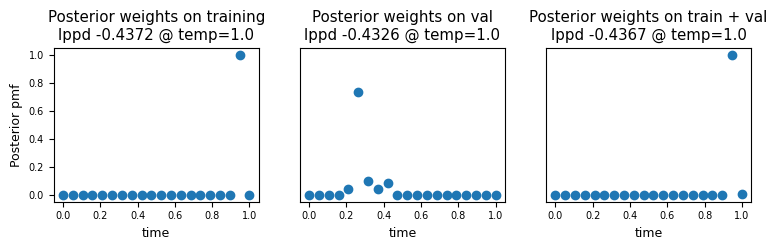

In [6]:
log_prob = logits_loaded['train']['logits']
targets = logits_loaded['train']['labels']
log_prob = jax.scipy.special.log_softmax(log_prob, axis=-1)

log_p_y = jnp.take_along_axis(log_prob, targets[None, :, None], axis=-1).squeeze(-1)  # (n_samples, n_valid)
log_p_D_train = jnp.sum(log_p_y, axis=-1)  # (n_samples,)

weights_train = _compute_posterior_weights(log_p_D_train, [1,]).squeeze()
perf_train = post_pred_performance(logits_loaded['test']['logits'], logits_loaded['test']['labels'], weights=weights_train, key_prefix="test_", num_bins=15)

log_prob = logits_loaded['val']['logits']
targets = logits_loaded['val']['labels']
log_prob = jax.scipy.special.log_softmax(log_prob, axis=-1)

log_p_y = jnp.take_along_axis(log_prob, targets[None, :, None], axis=-1).squeeze(-1)  # (n_samples, n_valid)
log_p_D_val = jnp.sum(log_p_y, axis=-1)  # (n_samples,)

weights_val = _compute_posterior_weights(log_p_D_val, [1,]).squeeze()
perf_val = post_pred_performance(logits_loaded['test']['logits'], logits_loaded['test']['labels'], weights=weights_val, key_prefix="test_", num_bins=15)

weights_all = _compute_posterior_weights(log_p_D_train + log_p_D_val, [1,]).squeeze()
perf_all = post_pred_performance(logits_loaded['test']['logits'], logits_loaded['test']['labels'], weights=weights_all, key_prefix="test_", num_bins=15)

fig, axs = plt.subplots(1, 3, figsize=(9, 2))
axs[0].set_title("Posterior weights on training\n" + f"lppd {perf_train['test_ll']:.4f} @ temp=1.0")
axs[0].scatter(np.linspace(0, 1, len(weights_train)), weights_train)
axs[1].set_title("Posterior weights on val\n" + f"lppd {perf_val['test_ll']:.4f} @ temp=1.0")
axs[1].scatter(np.linspace(0, 1, len(weights_val)), weights_val)
axs[2].set_title("Posterior weights on train + val\n" + f"lppd {perf_all['test_ll']:.4f} @ temp=1.0")
axs[2].scatter(np.linspace(0, 1, len(weights_all)), weights_all)
# set y label
axs[0].set_ylabel("Posterior weight")

for ax in axs:
    ax.set_ylim(-0.05, 1.05)
    ax.set_xlabel("time")
axs[0].set_ylabel("Posterior pmf")
# remove y axis of axs[1] and axs[2]
axs[1].set_yticks([])
axs[2].set_yticks([])
pass


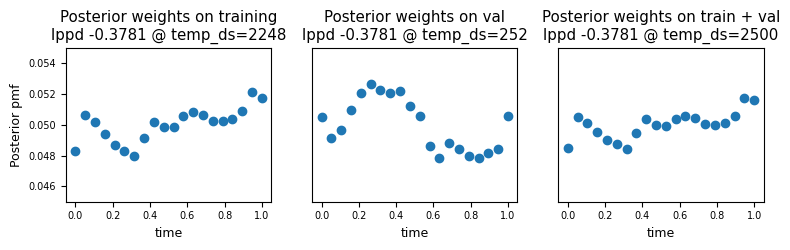

In [7]:
log_prob = logits_loaded['train']['logits']
targets = logits_loaded['train']['labels']
log_prob = jax.scipy.special.log_softmax(log_prob, axis=-1)

log_p_y = jnp.take_along_axis(log_prob, targets[None, :, None], axis=-1).squeeze(-1)  # (n_samples, n_valid)
log_p_D_train = jnp.sum(log_p_y, axis=-1)  # (n_samples,)

weights_train = _compute_posterior_weights(log_p_D_train, [logits_loaded['train']['labels'].shape[0]],).squeeze()
perf_train = post_pred_performance(logits_loaded['test']['logits'], logits_loaded['test']['labels'], weights=weights_train, key_prefix="test_", num_bins=15)

log_prob = logits_loaded['val']['logits']
targets = logits_loaded['val']['labels']
log_prob = jax.scipy.special.log_softmax(log_prob, axis=-1)

log_p_y = jnp.take_along_axis(log_prob, targets[None, :, None], axis=-1).squeeze(-1)  # (n_samples, n_valid)
log_p_D_val = jnp.sum(log_p_y, axis=-1)  # (n_samples,)

weights_val = _compute_posterior_weights(log_p_D_val, [logits_loaded['val']['labels'].shape[0]],).squeeze()
perf_val = post_pred_performance(logits_loaded['test']['logits'], logits_loaded['test']['labels'], weights=weights_val, key_prefix="test_", num_bins=15)

weights_all = _compute_posterior_weights(log_p_D_train + log_p_D_val, [logits_loaded['train']['labels'].shape[0] + logits_loaded['val']['labels'].shape[0]],).squeeze()
perf_all = post_pred_performance(logits_loaded['test']['logits'], logits_loaded['test']['labels'], weights=weights_all, key_prefix="test_", num_bins=15)

fig, axs = plt.subplots(1, 3, figsize=(9, 2))
axs[0].set_title("Posterior weights on training\n" + f"lppd {perf_train['test_ll']:.4f} @ temp_ds={logits_loaded['train']['labels'].shape[0]:.0f}")
axs[0].scatter(np.linspace(0, 1, len(weights_train)), weights_train)
axs[1].set_title("Posterior weights on val\n" + f"lppd {perf_val['test_ll']:.4f} @ temp_ds={logits_loaded['val']['labels'].shape[0]:.0f}")
axs[1].scatter(np.linspace(0, 1, len(weights_val)), weights_val)
axs[2].set_title("Posterior weights on train + val\n" + f"lppd {perf_all['test_ll']:.4f} @ temp_ds={logits_loaded['train']['labels'].shape[0] + logits_loaded['val']['labels'].shape[0]:.0f}")
axs[2].scatter(np.linspace(0, 1, len(weights_all)), weights_all)
# set y label
axs[0].set_ylabel("Posterior weight")

for ax in axs:
    ax.set_ylim(0.045, .055)
    ax.set_xlabel("time")
axs[0].set_ylabel("Posterior pmf")
# remove y axis of axs[1] and axs[2]
axs[1].set_yticks([])
axs[2].set_yticks([])
pass


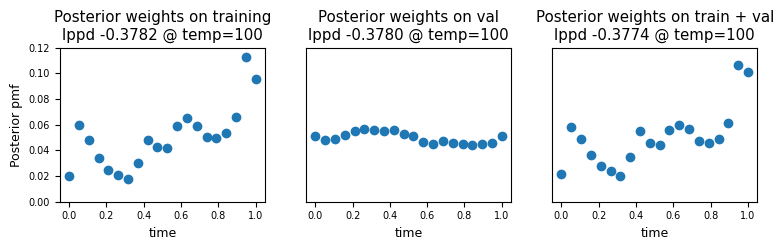

In [8]:
log_prob = logits_loaded['train']['logits']
targets = logits_loaded['train']['labels']
log_prob = jax.scipy.special.log_softmax(log_prob, axis=-1)

log_p_y = jnp.take_along_axis(log_prob, targets[None, :, None], axis=-1).squeeze(-1)  # (n_samples, n_valid)
log_p_D_train = jnp.sum(log_p_y, axis=-1)  # (n_samples,)

weights_train = _compute_posterior_weights(log_p_D_train, [100,]).squeeze()
perf_train = post_pred_performance(logits_loaded['test']['logits'], logits_loaded['test']['labels'], weights=weights_train, key_prefix="test_", num_bins=15)

log_prob = logits_loaded['val']['logits']
targets = logits_loaded['val']['labels']
log_prob = jax.scipy.special.log_softmax(log_prob, axis=-1)

log_p_y = jnp.take_along_axis(log_prob, targets[None, :, None], axis=-1).squeeze(-1)  # (n_samples, n_valid)
log_p_D_val = jnp.sum(log_p_y, axis=-1)  # (n_samples,)

weights_val = _compute_posterior_weights(log_p_D_val, [100,]).squeeze()
perf_val = post_pred_performance(logits_loaded['test']['logits'], logits_loaded['test']['labels'], weights=weights_val, key_prefix="test_", num_bins=15)

weights_all = _compute_posterior_weights(log_p_D_train + log_p_D_val, [100,]).squeeze()
perf_all = post_pred_performance(logits_loaded['test']['logits'], logits_loaded['test']['labels'], weights=weights_all, key_prefix="test_", num_bins=15)

fig, axs = plt.subplots(1, 3, figsize=(9, 2))
axs[0].set_title("Posterior weights on training\n" + f"lppd {perf_train['test_ll']:.4f} @ temp=100")
axs[0].scatter(np.linspace(0, 1, len(weights_train)), weights_train)
axs[1].set_title("Posterior weights on val\n" + f"lppd {perf_val['test_ll']:.4f} @ temp=100")
axs[1].scatter(np.linspace(0, 1, len(weights_val)), weights_val)
axs[2].set_title("Posterior weights on train + val\n" + f"lppd {perf_all['test_ll']:.4f} @ temp=100")
axs[2].scatter(np.linspace(0, 1, len(weights_all)), weights_all)
# set y label
axs[0].set_ylabel("Posterior weight")

for ax in axs:
    ax.set_ylim(-0.0, .12)
    ax.set_xlabel("time")
axs[0].set_ylabel("Posterior pmf")
# remove y axis of axs[1] and axs[2]
axs[1].set_yticks([])
axs[2].set_yticks([])
pass


In [10]:
# best temperature on val
temp_space = jnp.logspace(0, 6, 100000, endpoint=True)

log_prob = logits_loaded['train']['logits']
targets = logits_loaded['train']['labels']
log_prob = jax.scipy.special.log_softmax(log_prob, axis=-1)
log_p_y = jnp.take_along_axis(log_prob, targets[None, :, None], axis=-1).squeeze(-1)  # (n_samples, n_valid)
log_p_D_train = jnp.sum(log_p_y, axis=-1)  # (n_samples,)
weights_train = _compute_posterior_weights(log_p_D_train, temp_space).squeeze()

log_prob = logits_loaded['val']['logits']
targets = logits_loaded['val']['labels']
log_prob = jax.scipy.special.log_softmax(log_prob, axis=-1)
log_p_y = jnp.take_along_axis(log_prob, targets[None, :, None], axis=-1).squeeze(-1)  # (n_samples, n_valid)
log_p_D_val = jnp.sum(log_p_y, axis=-1)  # (n_samples,)
weights_val = _compute_posterior_weights(log_p_D_val, temp_space).squeeze()

weights_all = _compute_posterior_weights(log_p_D_train + log_p_D_val, temp_space).squeeze()


def perf(weights):
    return post_pred_performance(logits_loaded['val']['logits'], logits_loaded['val']['labels'], weights=weights)['ll']
perf_vec = jax.vmap(perf)(weights_all)
best_idx = jnp.argmax(perf_vec)
best_temp = temp_space[best_idx]
best_perf = perf_vec[best_idx]
print(f"Best temperature on val: {best_temp:.2f} with test ll {best_perf:.4f}")
post_pred_performance(logits_loaded['test']['logits'], logits_loaded['test']['labels'], weights=weights_all[best_idx], key_prefix=f"test_temp={best_temp:.1f}: ", num_bins=15)

Best temperature on val: 981928.19 with test ll -0.2795


{'test_temp=981928.2: ll': Array(-0.3781347, dtype=float32),
 'test_temp=981928.2: acc': Array(0.8308334, dtype=float32),
 'test_temp=981928.2: ece': Array(0.0509415, dtype=float32)}

#### test linear mode connect 

In [ ]:
run = wandb.Api().run("ddold/qwen_PtoC_seg/7lrgbp3s")

config, data, rng_key = load_config_and_data(run)
# env, params, rng_key = _setup_training_env(config, data, rng_key)
bma_weights, trainable_params, init_trainable_params, pretrained_params, last_trainable_params = load_checkpoint_new(run)

Dataset loaded: 2500 samples, 2 classes
Target token IDs: [[32]
 [33]]
Validation data are used
Training data: 2248 samples, Validation data: 252 samples
Control point fixed list: [1, 0, 0, 1, 0, 0, 1]
Setting num_epochs to 18 to match 10000 steps
Setting num_steps to 10116 to match 18 epochs
Found run: charmed-sweep-1 (7lrgbp3s)
Loaded last_trainable_params from 7lrgbp3s_last_trainable_params.npy
Loaded pretrained_params from 7lrgbp3s_pretrained_params.npy
Loaded trainable_params from 7lrgbp3s_trainable_params.npy
Loaded bma_weights from 7lrgbp3s_weights.npz


In [14]:
config.model_params.cp_fix = [1, 1, 1]
config.model_params.curve_segment = 1
env, params, rng_key = _setup_training_env(config, data, rng_key)

Using cosine rho schedule with total steps 10116
save best parameters


In [ ]:
pretrained_params = [p for p in pretrained_params if isinstance(p, dict)]
# map trainable_params to env.s_model.params
params['params'] = jax.tree.map(lambda m, p, *tp: jnp.stack(tp) if m else p, env.s_model.train_mask, params['params'], *pretrained_params)  


In [ ]:
logit_fn = setup_metrics(env.s_model, 8, *data.get('test'), n_samples=20, use_linspace=True, average=False, key_prefix='test_', num_bins_ece=15)
metric, out = logit_fn(rng_key, params)

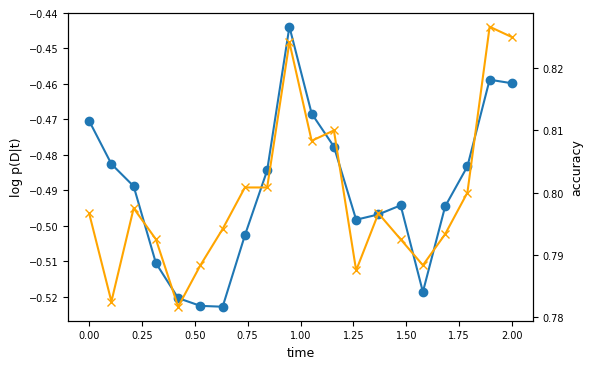

In [58]:
import matplotlib.pyplot as plt

logit = jax.scipy.special.log_softmax(out, axis=-1)
log_pmf = jnp.take_along_axis(logit, data.get('test')[2][None, :, None], axis=-1).squeeze(-1)  # (n_samples, n_valid)
log_p_D = jnp.mean(log_pmf, axis=-1)  # (n_samples,)
acc = jnp.mean(jnp.argmax(logit, axis=-1) == data.get('test')[2], axis=-1)  # (n_samples,)

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(np.linspace(0, env.s_model.t_max, len(log_p_D)), log_p_D, marker='o')
#twin x axis
ax2 = ax.twinx()
ax2.plot(np.linspace(0, env.s_model.t_max, len(acc)), acc, marker='x', color='orange')
ax.set_xlabel("time")
ax.set_ylabel("log p(D|t)")
ax2.set_ylabel("accuracy")
plt.show()

#### test 4 DE performance

In [9]:
import wandb
run = wandb.Api().run("ddold/qwen_PtoC_seg/c6q5eup1")
config, data, rng_key = load_config_and_data(run)
# env, params, rng_key = _setup_training_env(config, data, rng_key)

bma_weights, trainable_params, init_trainable_params, pretrained_params, last_trainable_params = load_checkpoint_new(run)

Dataset loaded: 2500 samples, 2 classes
Target token IDs: [[32]
 [33]]
Validation data are used
Training data: 2248 samples, Validation data: 252 samples
Control point fixed list: [1, 0, 0, 1, 0, 0, 1, 0, 0, 1, 0, 0, 1]
Setting num_epochs to 18 to match 10000 steps
Setting num_steps to 10116 to match 18 epochs
Found run: serene-sweep-9 (c6q5eup1)
Loaded last_trainable_params from c6q5eup1_last_trainable_params.npy
Loaded pretrained_params from c6q5eup1_pretrained_params.npy
Loaded trainable_params from c6q5eup1_trainable_params.npy
Loaded bma_weights from c6q5eup1_weights.npz


In [16]:
pretrained_params = [jp for jp in pretrained_params if jp != False] # filter out any False entries

logits = []
with config.as_pretrain() as pt_config:
    env, params, rng_key = _setup_training_env(config=pt_config, data=data, rng_key=rng_key)
    # set lora_rho = 0
    params = params = env.s_model.set_lora_rho(rho_s=0.0, rho_w=0.0, params=params)

    pred_fn = setup_metrics(env.s_model, 8, *data.get('test'), n_samples=1, use_linspace=True, key_prefix='test_', num_bins_ece=15, t_sample_fn=None, t_max=env.s_model.t_max)
    
    for de_param in pretrained_params:
        params['params'] = jax.tree.map(lambda m, tp, p: tp if m else p, env.s_model.train_mask, de_param, params['params'])
        metric, out = pred_fn(rng_key, params)
        logits.append(jax.nn.log_softmax(out))

logits = jnp.concatenate(logits, axis=0)  # (n_samples, n_valid, n_classes)
logits.shape

Using cosine rho schedule with total steps 5058
save best parameters


(5, 1200, 2)

In [26]:
def lppd(logits, targets):
    log_pmf = jnp.take_along_axis(logits, targets[None, :, None], axis=-1).squeeze(-1)  # (n_samples, n_valid)
    def single(n_samples):
        log_pmf_ = log_pmf[:n_samples]
        log_ppd = jax.scipy.special.logsumexp(log_pmf_, axis=0) - jnp.log(n_samples)  # log p(D) = logsumexp(log p(D|t)) - log n_samples
        return jnp.mean(log_ppd)

    return {f"lppd_DE({n})": single(n).item() for n in range(1, logits.shape[0] + 1)}

lppd(logits, data.get('test')[2])

{'lppd_DE(1)': -0.4579981565475464,
 'lppd_DE(2)': -0.3997029662132263,
 'lppd_DE(3)': -0.387946218252182,
 'lppd_DE(4)': -0.3759646415710449,
 'lppd_DE(5)': -0.37385138869285583}

In [16]:
params['params']['layers_0']['self_attn']['q_proj']['kernel'].shape

{'A': (8, 3584), 'B': (3584, 8), 'w0': (3584, 3584)}

#### compare DE on ARC dataset and compare with sampling missmatch

In [8]:
import wandb
run = wandb.Api().run("ddold/qwen_PtoC_seg/ebv2pnli")
config, data, rng_key = load_config_and_data(run)
env, params, rng_key = _setup_training_env(config, data, rng_key)

bma_weights, trainable_params, init_trainable_params, pretrained_params, last_trainable_params = load_checkpoint_new(run)
env

Dataset loaded: 1100 samples, 5 classes
Target token IDs: [[32]
 [33]
 [34]
 [35]
 [36]]
Validation data are used
Training data: 988 samples, Validation data: 112 samples
Control point fixed list: [1, 0, 0, 1, 0, 0, 1, 0, 0, 1, 0, 0, 1]
Setting num_epochs to 41 to match 10000 steps
Setting num_steps to 10127 to match 41 epochs
Using cosine rho schedule with total steps 10127
save best parameters
Found run: worldly-sweep-57 (ebv2pnli)
Loaded last_trainable_params from ebv2pnli_last_trainable_params.npy
Loaded pretrained_params from ebv2pnli_pretrained_params.npy
Loaded trainable_params from ebv2pnli_trainable_params.npy
Loaded bma_weights from ebv2pnli_weights.npz


TrainingEnv(s_model=<src.subspace_curve.LoRACategorySubspace object at 0x7f9f74040bb0>, optimizer=GradientTransformationExtraArgs(init=<function chain.<locals>.init_fn at 0x7f9f74034940>, update=<function chain.<locals>.update_fn at 0x7f9f740349d0>), t_sample_fn=<function _setup_t_sample_fn.<locals>.t_sample_fn_v2 at 0x7f9f74203760>, rho_scheduler=<function _setup_rho_scheduler.<locals>.rho_scheduler at 0x7f9f74035bd0>, valid_metrics_fn=<function _setup_validation.<locals>.valid_metrics_fn at 0x7f9f740353f0>, empty_metric=({'val_mean_loss': Array(inf, dtype=float32), 'val_mean_acc': Array(-inf, dtype=float32), 'val_mean_ece': Array(inf, dtype=float32), 'val_bma_ll': Array(-inf, dtype=float32), 'val_bma_acc': Array(-inf, dtype=float32), 'val_bma_ece': Array(inf, dtype=float32)}, None), get_best_params=<function _setup_validation.<locals>.get_best_params at 0x7f9f740352d0>, train_step=<PjitFunction of <function _setup_training_env.<locals>._scan_jit at 0x7f9f740340d0>>)

In [9]:
pretrained_params = [jp for jp in pretrained_params if jp != False] # filter out any False entries

logits = []
with config.as_pretrain() as pt_config:
    env, params, rng_key = _setup_training_env(config=pt_config, data=data, rng_key=rng_key)
    # set lora_rho = 0
    params = params = env.s_model.set_lora_rho(rho_s=0.0, rho_w=0.0, params=params)

    pred_fn = setup_metrics(env.s_model, 8, *data.get('test'), n_samples=1, use_linspace=True, key_prefix='test_', num_bins_ece=15, t_sample_fn=None, t_max=env.s_model.t_max)
    
    for de_param in pretrained_params:
        params['params'] = jax.tree.map(lambda m, tp, p: tp if m else p, env.s_model.train_mask, de_param, params['params'])
        metric, out = pred_fn(rng_key, params)
        logits.append(out)

logits = jnp.concatenate(logits, axis=0)  # (n_samples, n_valid, n_classes)
logits.shape

Using cosine rho schedule with total steps 4940
save best parameters


(5, 200, 5)

In [11]:
np.save("logits_ARC_test(1).npy", np.array(logits))

In [10]:
logits = jax.nn.log_softmax(logits, axis=-1)

In [11]:
def lppd(logits, targets):
    log_pmf = jnp.take_along_axis(logits, targets[None, :, None], axis=-1).squeeze(-1)  # (n_samples, n_valid)
    def single(n_samples):
        log_pmf_ = log_pmf[:n_samples]
        log_ppd = jax.scipy.special.logsumexp(log_pmf_, axis=0) - jnp.log(n_samples)  # log p(D) = logsumexp(log p(D|t)) - log n_samples
        return jnp.mean(log_ppd)

    return {f"lppd_DE({n})": single(n).item() for n in range(1, logits.shape[0] + 1)}

lppd(logits, data.get('test')[2])

{'lppd_DE(1)': -0.40733078122138977,
 'lppd_DE(2)': -0.3291309177875519,
 'lppd_DE(3)': -0.27304401993751526,
 'lppd_DE(4)': -0.27343279123306274,
 'lppd_DE(5)': -0.27674880623817444}

In [15]:
16*12

192

In [13]:
logits.shape

(5, 200, 5)

In [16]:
def lppd(logits, targets):
    log_pmf = jnp.take_along_axis(logits, targets[None, :, None], axis=-1).squeeze(-1)  # (n_samples, n_valid)
    def single(n_samples):
        log_pmf_ = log_pmf[:n_samples]
        log_ppd = jax.scipy.special.logsumexp(log_pmf_, axis=0) - jnp.log(n_samples)  # log p(D) = logsumexp(log p(D|t)) - log n_samples
        return jnp.mean(log_ppd)

    return {f"lppd_DE({n})": single(n).item() for n in range(1, logits.shape[0] + 1)}

lppd(logits[:,:192], data.get('test')[2][:192])

{'lppd_DE(1)': -0.3631918132305145,
 'lppd_DE(2)': -0.30418530106544495,
 'lppd_DE(3)': -0.2415757179260254,
 'lppd_DE(4)': -0.2405472844839096,
 'lppd_DE(5)': -0.24284431338310242}

In [14]:
def single_lppd(logits, targets):
    log_pmf = jnp.take_along_axis(logits, targets[:, None], axis=-1).squeeze(-1)  # (n_samples, n_valid)
    # log_ppd = jax.scipy.special.logsumexp(log_pmf, axis=0) - jnp.log(n_samples)  # log p(D) = logsumexp(log p(D|t)) - log n_samples
    return jnp.mean(log_pmf, axis=0)
jax.vmap(single_lppd, in_axes=(0, None))(logits, data.get('test')[2])

Array([-0.40733078, -0.43635866, -0.44551563, -0.41195768, -0.41949812],      dtype=float32)

In [9]:
def single_lppd(logits, targets):
    log_pmf = jnp.take_along_axis(logits, targets[:, None], axis=-1).squeeze(-1)  # (n_samples, n_valid)
    # log_ppd = jax.scipy.special.logsumexp(log_pmf, axis=0) - jnp.log(n_samples)  # log p(D) = logsumexp(log p(D|t)) - log n_samples
    return jnp.mean(log_pmf, axis=0)
jax.vmap(single_lppd, in_axes=(0, None))(logits, data.get('test')[2])

Array([-0.40733078, -0.43635866, -0.44551563, -0.41195768, -0.41949812],      dtype=float32)

In [16]:
config.model_params.cp_fix

[1, 0, 0, 1, 0, 0, 1, 0, 0, 1, 0, 0, 1]

In [26]:
data, unique_target_ids, rng_key = _prepare_datasets(
        rng_key,
        dataset_path="artifacts/ARC-Challenge_dataset:v0",
        val_percentage=0.1,
        batch_size=4,
        smoke_test=False,
        logger=False)
data.get('train')[2].shape, data.get('val')[2].shape, data.get('test')[2].shape

Dataset loaded: 1100 samples, 5 classes
Target token IDs: [[32]
 [33]
 [34]
 [35]
 [36]]
Validation data are used
Training data: 988 samples, Validation data: 112 samples


((988,), (112,), (200,))

In [32]:
for ds in ['ARC-Challenge', 'ARC-Easy', "obqa", "winogrande_m", "winogrande_s"]:
    data, unique_target_ids, rng_key = _prepare_datasets(
            rng_key,
            dataset_path=f"artifacts/{ds}_dataset:v0",
            val_percentage=0.1,
            batch_size=4,
            smoke_test=False,
            logger=False)
    # one line ds shape printout
    print("*****"*5)
    print(f"Dataset Shape: {ds}, {data.get('train')[2].shape}, {data.get('val')[2].shape}, {data.get('test')[2].shape}")
    print("*****"*5)

Dataset loaded: 1100 samples, 5 classes
Target token IDs: [[32]
 [33]
 [34]
 [35]
 [36]]
Validation data are used
Training data: 988 samples, Validation data: 112 samples
*************************
Dataset Shape: ARC-Challenge, (988,), (112,), (200,)
*************************
Dataset loaded: 2200 samples, 5 classes
Target token IDs: [[32]
 [33]
 [34]
 [35]
 [36]]
Validation data are used
Training data: 1980 samples, Validation data: 220 samples
*************************
Dataset Shape: ARC-Easy, (1980,), (220,), (500,)
*************************
Dataset loaded: 4900 samples, 4 classes
Target token IDs: [[32]
 [33]
 [34]
 [35]]
Validation data are used
Training data: 4408 samples, Validation data: 492 samples
*************************
Dataset Shape: obqa, (4408,), (492,), (500,)
*************************
Dataset loaded: 2500 samples, 2 classes
Target token IDs: [[32]
 [33]]
Validation data are used
Training data: 2248 samples, Validation data: 252 samples
*************************
Dataset 

#### compare singular values

In [10]:
import wandb
from src.subspace_curve import LoraAbstractParams

run = wandb.Api().run("ddold/qwen_PtoC_seg/ebv2pnli") # ARC-Challenge
run = wandb.Api().run("ddold/qwen_PtoC_seg/6fjczmew") # winogrand_s
config, data, rng_key = load_config_and_data(run)
env, params, rng_key = _setup_training_env(config, data, rng_key)

bma_weights, trainable_params, init_trainable_params, pretrained_params, last_trainable_params = load_checkpoint_new(run)
env

Dataset loaded: 600 samples, 2 classes
Target token IDs: [[32]
 [33]]
Validation data are used
Training data: 540 samples, Validation data: 60 samples
Control point fixed list: [1, 0, 0, 1, 0, 0, 1, 0, 0, 1, 0, 0, 1]
Setting num_epochs to 75 to match 10000 steps
Setting num_steps to 10125 to match 75 epochs


Using cosine rho schedule with total steps 10125
save best parameters
Found run: comfy-sweep-41 (6fjczmew)
Loaded last_trainable_params from 6fjczmew_last_trainable_params.npy
Loaded pretrained_params from 6fjczmew_pretrained_params.npy
Loaded trainable_params from 6fjczmew_trainable_params.npy
Loaded bma_weights from 6fjczmew_weights.npz


TrainingEnv(s_model=<src.subspace_curve.LoRACategorySubspace object at 0x7f6eb0582800>, optimizer=GradientTransformationExtraArgs(init=<function chain.<locals>.init_fn at 0x7f6b207067a0>, update=<function chain.<locals>.update_fn at 0x7f6b20706680>), t_sample_fn=<function _setup_t_sample_fn.<locals>.t_sample_fn_v2 at 0x7f6eb05871c0>, rho_scheduler=<function _setup_rho_scheduler.<locals>.rho_scheduler at 0x7f6eb02c8820>, valid_metrics_fn=<function _setup_validation.<locals>.valid_metrics_fn at 0x7f6b20704ee0>, empty_metric=({'val_mean_loss': Array(inf, dtype=float32), 'val_mean_acc': Array(-inf, dtype=float32), 'val_mean_ece': Array(inf, dtype=float32), 'val_bma_ll': Array(-inf, dtype=float32), 'val_bma_acc': Array(-inf, dtype=float32), 'val_bma_ece': Array(inf, dtype=float32)}, None), get_best_params=<function _setup_validation.<locals>.get_best_params at 0x7f6b20704f70>, train_step=<PjitFunction of <function _setup_training_env.<locals>._scan_jit at 0x7f6b20706b00>>)

In [11]:
print(params['params']['layers_0']['self_attn']['q_proj']['kernel'].shape)
trainable_params['layers_0']['self_attn']['q_proj']['kernel'].shape

{'A': (13, 8, 3584), 'B': (13, 3584, 8), 'w0': (3584, 3584)}


{'A': (13, 8, 3584), 'B': (13, 3584, 8), 'w0': (0,)}

In [12]:
# merge trainable_params into params['params'] according to env.s_model.train_mask

params = env.s_model.set_lora_rho(rho_s=0.0, rho_w=0., params=params)
params['params'] = jax.tree.map(lambda m, tp, p: tp if m else p, env.s_model.train_mask, trainable_params, params['params'])

[8.0907568e-02 5.1453829e-02 3.6975317e-02 3.0385332e-02 2.8246609e-02
 2.4179896e-02 1.9211115e-02 1.8530589e-02 1.4915708e-08 1.3573198e-08]


Array(8, dtype=int32)

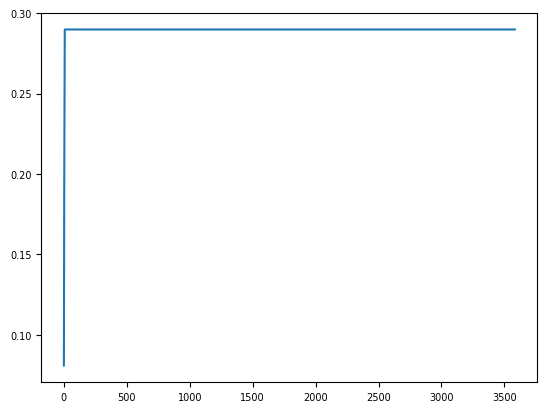

In [11]:
from src.subspace_curve import LoraAbstractParams
def svd_per_layer(x: LoraAbstractParams):
    # get curve point
    dw = x.B @ x.A
    scale = x.lora_alpha / x.B.shape[-1]
    dw = dw * scale
    U, s, Vh = jnp.linalg.svd(dw, full_matrices=False)
    # return jnp.sum(s > 1e-2)  # example threshold for significant singular values
    return s  # example threshold for significant singular values

def rank_per_layer(x: LoraAbstractParams, threshold=1e-2):
    s = svd_per_layer(x)
    return jnp.sum(s > threshold)  # example threshold for significant singular values

bezier = env.s_model.bezier
coeff = bezier(jnp.array([0.,]))
p_c = jax.tree.map(lambda p, m: jnp.einsum(
                'k,k...->...', coeff, p).astype(p.dtype) if m else p, params['params'], env.s_model.curve_mask)

tt = jax.tree.map(svd_per_layer, p_c['layers_0']['self_attn']['q_proj']['kernel'], is_leaf=lambda x: isinstance(x, LoraAbstractParams))
plt.plot(tt.cumsum())
print(tt[:10])
rank_per_layer(p_c['layers_0']['self_attn']['q_proj']['kernel'], threshold=1e-5)

In [13]:
from einshape import jax_einshape as es
import dataclasses

class SVDMode:
    column = 'column'
    row = 'row'
    sum = 'sum'
    mean = 'mean'

# def de_lora_merge(x, de_idx):
#     B = jnp.take(x.B, de_idx, axis=0)
#     A = jnp.take(x.A, de_idx, axis=0)
#     return jnp.einsum('kij,kjl->kil', B, A) # dw = B @ A per de_member

# def de_lora_sigma(x, de_idx, mode=SVDMode.column):
#     dw = de_lora_merge(x, de_idx)
#     if mode == SVDMode.row:
#         dw = es("kij->(ki)j", dw)
#     elif mode == SVDMode.column:
#         dw = es("kij->i(kj)", dw)
#     elif mode == SVDMode.sum:
#         dw = jnp.sum(dw, axis=0)  # sum over k dimension
#     elif mode == SVDMode.mean:
#         dw = jnp.mean(dw, axis=0)  # mean over k dimension
#     s = jnp.linalg.svd(dw, full_matrices=False, compute_uv=False)
#     return s

def lora_sigma(x, mode=SVDMode.column):
    dw = jnp.einsum('kij,kjl->kil', x.B, x.A)
    if mode == SVDMode.row:
        dw = es("kij->(ki)j", dw)
    elif mode == SVDMode.column:
        dw = es("kij->i(kj)", dw)
    elif mode == SVDMode.sum:
        dw = jnp.sum(dw, axis=0)  # sum over k dimension
    elif mode == SVDMode.mean:
        dw = jnp.mean(dw, axis=0)  # mean over k dimension
    s = jnp.linalg.svd(dw, full_matrices=False, compute_uv=False)
    return s



In [14]:
de_idx = jnp.nonzero(jnp.array(config.model_params.cp_fix))[0]
de_idx = jax.device_put(de_idx, jax.devices("cpu")[0])  # ensure de_idx is on CPU for SVD computation
pp = jax.device_put(params['params'], jax.devices("cpu")[0])  # move params to CPU for SVD computation
de_params = jax.tree.map(lambda p, m: jnp.take(p, de_idx, axis=0) if m else jnp.array([], dtype=jnp.float32, device=jax.devices("cpu")[0]), pp, env.s_model.curve_mask)

def set_t(num_curve_points=40):
    t = jnp.linspace(0, env.s_model.t_max, num_curve_points)
    def curve_points(p):
        def single_curve_point(t):
            bezier = env.s_model.bezier
            coeff = bezier(jnp.array([t,]))
            p_c = jnp.einsum('k,k...->...', coeff, p).astype(p.dtype)
            return p_c
        return jax.vmap(single_curve_point)(t)
    return curve_points

curve_points = jax.tree.map(lambda p, m: set_t(num_curve_points=100)(p) if m else jnp.array([]), pp, env.s_model.curve_mask)
print("Shape cps:", pp['layers_0']['self_attn']['q_proj']['kernel'].shape)
print("Shape DE:", de_params['layers_0']['self_attn']['q_proj']['kernel'].shape)
print("Shape Curve_points:", curve_points['layers_0']['self_attn']['q_proj']['kernel'].shape)

Shape cps: {'A': (13, 8, 3584), 'B': (13, 3584, 8), 'w0': (3584, 3584)}
Shape DE: {'A': (5, 8, 3584), 'B': (5, 3584, 8), 'w0': (0,)}
Shape Curve_points: {'A': (100, 8, 3584), 'B': (100, 3584, 8), 'w0': (0,)}


In [15]:
de_singular_values = jax.tree.map(lambda x: lora_sigma(x, mode=SVDMode.mean) if isinstance(x, LoraAbstractParams) else jnp.array([]), de_params, is_leaf=lambda x: isinstance(x, LoraAbstractParams))
def rank_per_layer(s, threshold=1e-2):
    return jnp.array([jnp.sum(s > threshold)])
rank_layer = jax.tree.map(lambda s: rank_per_layer(s, threshold=1e-5), de_singular_values)
rank_layer = [rl for rl in jax.tree.leaves(rank_layer) if rl > 0]
rank_layer = jnp.concatenate(rank_layer)
rank_layer

Array([40, 40, 40, 40, 40, 40, 40, 40, 40, 40, 40, 40, 40, 40, 40, 40, 40,
       40, 40, 40, 40, 40, 40, 40, 40, 40, 40, 40, 40, 40, 40, 40, 40, 40,
       40, 40, 40, 40, 40, 40, 40, 40, 40, 40, 40, 40, 40, 40, 40, 40, 40,
       40, 40, 40, 40, 40,  2], dtype=int32)

In [53]:
### Curve

In [15]:
curve_singular_per_layer = jax.tree.map(lambda x: lora_sigma(x, mode=SVDMode.mean) if isinstance(x, LoraAbstractParams) else jnp.array([]), pp, is_leaf=lambda x: isinstance(x, LoraAbstractParams))

curve_rank_layer = jax.tree.map(lambda s: rank_per_layer(s, threshold=1e-5), curve_singular_per_layer)
curve_rank_layer = [rl for rl in jax.tree.leaves(curve_rank_layer) if rl > 0]
curve_rank_layer = jnp.concatenate(curve_rank_layer)
curve_rank_layer

Array([104, 104, 104, 104, 104, 104, 104, 104, 104, 104, 104, 104, 104,
       104, 104, 104, 104, 104, 104, 104, 104, 104, 104, 104, 104, 104,
       104, 104, 104, 104, 104, 104, 104, 104, 104, 104, 104, 104, 104,
       104, 104, 104, 104, 104, 104, 104, 104, 104, 104, 104, 104, 104,
       104, 104, 104, 104,   2], dtype=int32)

In [16]:
curve_point_singular_per_layer = jax.tree.map(lambda x: lora_sigma(x, mode=SVDMode.mean) if isinstance(x, LoraAbstractParams) else jnp.array([]), curve_points, is_leaf=lambda x: isinstance(x, LoraAbstractParams))

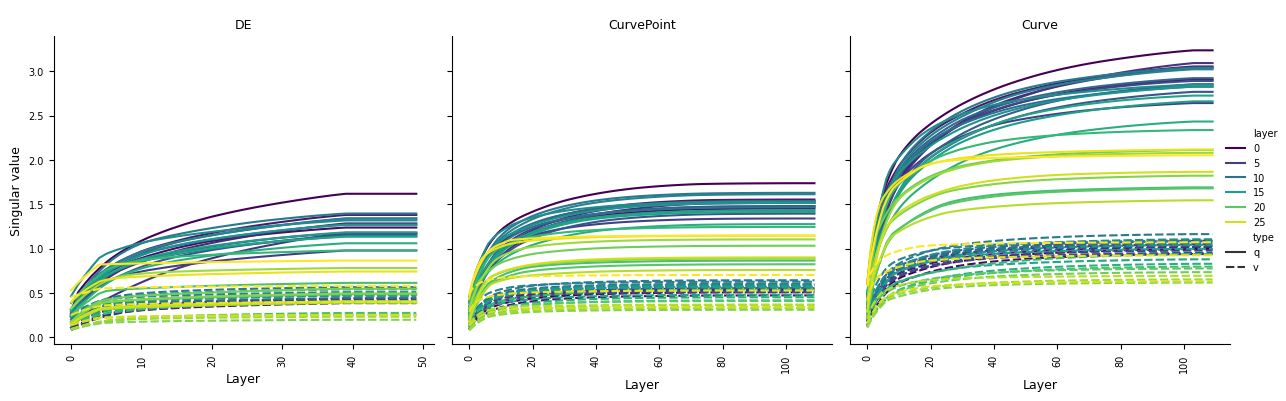

In [ ]:
names = []
singulars = []
types = []
layers = []
for p, s in jax.tree.leaves_with_path(curve_singular_per_layer):
    if s.shape[0] > 0:
        name = '/'.join(str(k.key) for k in p)
        names.append(name)
        singulars.append(s[:110])
        types.append("v" if "v_proj" in name else "q" if "q_proj" in name else "k" if "k_proj" in name else "o" if "o_proj" in name else "other")
        layers.append(str(p[0].key).split('_')[1])
df_curve = pd.DataFrame({"name": names, "singular_values": singulars, "type": types, "layer": layers})
df_curve['layer'] = df_curve['layer'].apply(lambda x: int(x) if x.isdigit() else -1)
df_curve['Method'] = "Curve"

names = []
singulars = []
types = []
layers = []
for p, s in jax.tree.leaves_with_path(curve_point_singular_per_layer):
    if s.shape[0] > 0:
        name = '/'.join(str(k.key) for k in p)
        names.append(name)
        singulars.append(s[:110])
        types.append("v" if "v_proj" in name else "q" if "q_proj" in name else "k" if "k_proj" in name else "o" if "o_proj" in name else "other")
        layers.append(str(p[0].key).split('_')[1])
df_curve_point = pd.DataFrame({"name": names, "singular_values": singulars, "type": types, "layer": layers})
df_curve_point['layer'] = df_curve_point['layer'].apply(lambda x: int(x) if x.isdigit() else -1)
df_curve_point['Method'] = "CurvePoint"

names = []
singulars = []
types = []
layers = []
for p, s in jax.tree.leaves_with_path(de_singular_values):
    if s.shape[0] > 0:
        name = '/'.join(str(k.key) for k in p)
        names.append(name)
        singulars.append(s[:50])
        types.append("v" if "v_proj" in name else "q" if "q_proj" in name else "k" if "k_proj" in name else "o" if "o_proj" in name else "other")
        layers.append(str(p[0].key).split('_')[1])
df = pd.DataFrame({"name": names, "singular_values": singulars, "type": types, "layer": layers})
df['Method'] = "DE"
df['layer'] = df['layer'].apply(lambda x: int(x) if x.isdigit() else -1)

df_cmp = pd.concat([df, df_curve, df_curve_point], ignore_index=True)
df_cmp = df_cmp[df_cmp['type'].isin(['q', 'v',])]  # filter to only attention projections
df_cmp = df_cmp.explode("singular_values", ignore_index=True)
df_cmp["singular_values"] = df_cmp["singular_values"].astype(float)
df_cmp["sv_cumsum"] = df_cmp.groupby(["Method", "name"])["singular_values"].cumsum()
df_cmp["sv_idx"] = df_cmp.groupby(["Method", "name"]).cumcount() + 1
df_cmp.sort_values(["Method", "layer", "type"], inplace=True)

g = sns.relplot(
    data=df_cmp,
    kind="line",
    x="sv_idx",
    y="sv_cumsum",
    hue="layer",
    style="type",
    col="Method",
    col_order=["DE", "CurvePoint", "Curve"],
    height=4,
    aspect=1.,
    palette="viridis",
    facet_kws={'sharex': False},
)

g.set_axis_labels("Layer", "Singular value")
g.set_titles("{col_name}")
for ax in g.axes.flat:
    ax.tick_params(axis="x", rotation=90)
g.add_legend(loc='upper left', bbox_to_anchor=(1, 1))
g.tight_layout()

In [17]:
np.save("de_singular_values.npy", de_singular_values)
np.save("curve_point_singular_values.npy", curve_point_singular_per_layer)

In [ ]:
de_singular_values = np.load("de_singular_values.npy", allow_pickle=True).item()
curve_point_singular_per_layer = np.load("curve_point_singular_values.npy", allow_pickle=True).item()

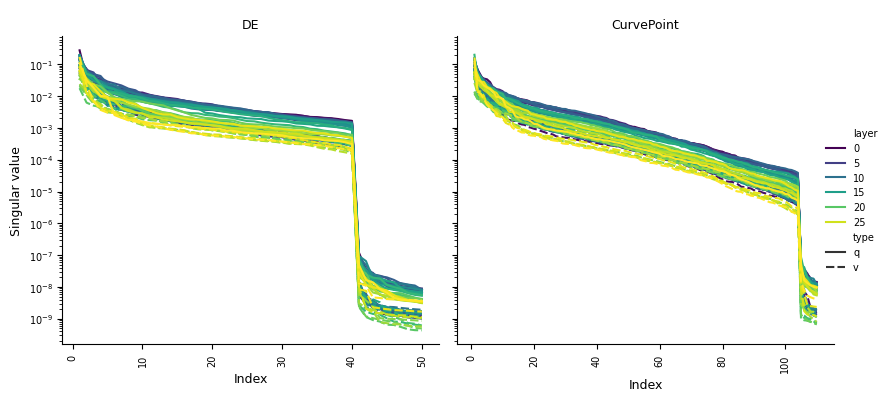

In [38]:
names = []
singulars = []
types = []
layers = []
for p, s in jax.tree.leaves_with_path(curve_point_singular_per_layer):
    if s.shape[0] > 0:
        name = '/'.join(str(k.key) for k in p)
        names.append(name)
        singulars.append(s[:110])
        types.append("v" if "v_proj" in name else "q" if "q_proj" in name else "k" if "k_proj" in name else "o" if "o_proj" in name else "other")
        layers.append(str(p[0].key).split('_')[1])
df_curve_point = pd.DataFrame({"name": names, "singular_values": singulars, "type": types, "layer": layers})
df_curve_point['layer'] = df_curve_point['layer'].apply(lambda x: int(x) if x.isdigit() else -1)
df_curve_point['Method'] = "CurvePoint"

names = []
singulars = []
types = []
layers = []
for p, s in jax.tree.leaves_with_path(de_singular_values):
    if s.shape[0] > 0:
        name = '/'.join(str(k.key) for k in p)
        names.append(name)
        singulars.append(s[:50])
        types.append("v" if "v_proj" in name else "q" if "q_proj" in name else "k" if "k_proj" in name else "o" if "o_proj" in name else "other")
        layers.append(str(p[0].key).split('_')[1])
df = pd.DataFrame({"name": names, "singular_values": singulars, "type": types, "layer": layers})
df['Method'] = "DE"
df['layer'] = df['layer'].apply(lambda x: int(x) if x.isdigit() else -1)

df_cmp = pd.concat([df, df_curve_point], ignore_index=True)
df_cmp = df_cmp[df_cmp['type'].isin(['q', 'v',])]  # filter to only attention projections
df_cmp = df_cmp.explode("singular_values", ignore_index=True)
df_cmp["singular_values"] = df_cmp["singular_values"].astype(float)
df_cmp["sv_cumsum"] = df_cmp.groupby(["Method", "name"])["singular_values"].cumsum()
df_cmp["sv_idx"] = df_cmp.groupby(["Method", "name"]).cumcount() + 1
df_cmp.sort_values(["Method", "layer", "type"], inplace=True)

g = sns.relplot(
    data=df_cmp,
    kind="line",
    x="sv_idx",
    y="singular_values",
    hue="layer",
    style="type",
    col="Method",
    col_order=["DE", "CurvePoint"],
    height=4,
    aspect=1.,
    palette="viridis",
    facet_kws={'sharex': False},
)

g.set_axis_labels("Index", "Singular value")
g.set_titles("{col_name}")

for ax in g.axes.flat:
    ax.set_yscale("log")
    ax.tick_params(axis="x", rotation=90)
g.add_legend(loc='upper left', bbox_to_anchor=(1, 1))
g.tight_layout()

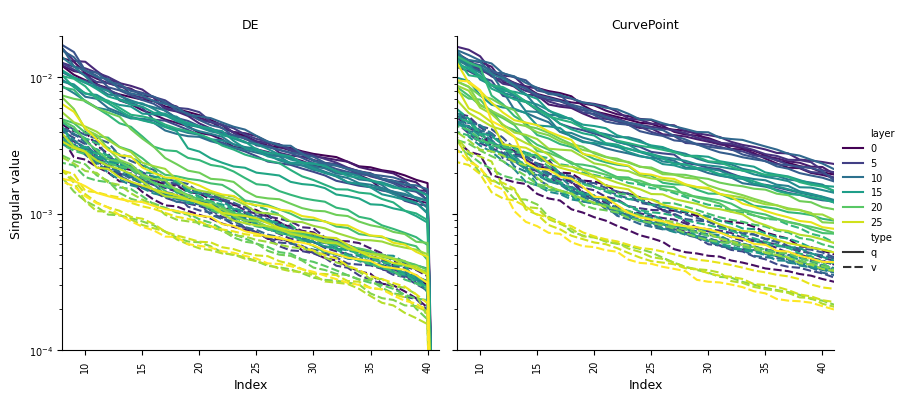

In [40]:
names = []
singulars = []
types = []
layers = []
for p, s in jax.tree.leaves_with_path(curve_point_singular_per_layer):
    if s.shape[0] > 0:
        name = '/'.join(str(k.key) for k in p)
        names.append(name)
        singulars.append(s[:110])
        types.append("v" if "v_proj" in name else "q" if "q_proj" in name else "k" if "k_proj" in name else "o" if "o_proj" in name else "other")
        layers.append(str(p[0].key).split('_')[1])
df_curve_point = pd.DataFrame({"name": names, "singular_values": singulars, "type": types, "layer": layers})
df_curve_point['layer'] = df_curve_point['layer'].apply(lambda x: int(x) if x.isdigit() else -1)
df_curve_point['Method'] = "CurvePoint"

names = []
singulars = []
types = []
layers = []
for p, s in jax.tree.leaves_with_path(de_singular_values):
    if s.shape[0] > 0:
        name = '/'.join(str(k.key) for k in p)
        names.append(name)
        singulars.append(s[:50])
        types.append("v" if "v_proj" in name else "q" if "q_proj" in name else "k" if "k_proj" in name else "o" if "o_proj" in name else "other")
        layers.append(str(p[0].key).split('_')[1])
df = pd.DataFrame({"name": names, "singular_values": singulars, "type": types, "layer": layers})
df['Method'] = "DE"
df['layer'] = df['layer'].apply(lambda x: int(x) if x.isdigit() else -1)

df_cmp = pd.concat([df, df_curve_point], ignore_index=True)
df_cmp = df_cmp[df_cmp['type'].isin(['q', 'v',])]  # filter to only attention projections
df_cmp = df_cmp.explode("singular_values", ignore_index=True)
df_cmp["singular_values"] = df_cmp["singular_values"].astype(float)
df_cmp["sv_cumsum"] = df_cmp.groupby(["Method", "name"])["singular_values"].cumsum()
df_cmp["sv_idx"] = df_cmp.groupby(["Method", "name"]).cumcount() + 1
df_cmp.sort_values(["Method", "layer", "type"], inplace=True)

g = sns.relplot(
    data=df_cmp,
    kind="line",
    x="sv_idx",
    y="singular_values",
    hue="layer",
    style="type",
    col="Method",
    col_order=["DE", "CurvePoint"],
    height=4,
    aspect=1.,
    palette="viridis",
    facet_kws={'sharex': False},
)

g.set_axis_labels("Index", "Singular value")
g.set_titles("{col_name}")

for ax in g.axes.flat:
    ax.set_yscale("log")
    ax.tick_params(axis="x", rotation=90)
g.add_legend(loc='upper left', bbox_to_anchor=(1.02, 1))
# set y limit to (1e-5
g.axes[0, 0].set_ylim(1e-4, 2e-2)
g.axes[0, 0].set_xlim(8, 41)
g.axes[0, 1].set_ylim(1e-4, 2e-2)
g.axes[0, 1].set_xlim(8, 41)
g.tight_layout()

In [19]:
# load VI results

In [20]:
import numpy as np
blob_singulars = np.load("../BayesAdapt/checkpoints/blob/Qwen/Qwen2.5-7B/winogrande_m/test_svd-blob-winogrande_m-sample40-eps0.05-kllr0.01-beta0.2-gamma8-seed1/singular_values.npy", allow_pickle=True).item()
blob_singulars

{'model.layers.0.self_attn.q_proj': array([1.0590504e+00, 7.0840973e-01, 6.3399976e-01, ..., 2.9869252e-08,
        2.9791901e-08, 7.3140463e-09], dtype=float32),
 'model.layers.0.self_attn.v_proj': array([4.30937499e-01, 2.65008330e-01, 2.13608548e-01, 2.08657280e-01,
        1.96411967e-01, 1.71777993e-01, 1.62581772e-01, 1.56163514e-01,
        3.28491922e-07, 2.42818771e-07, 1.56854924e-07, 1.48617787e-07,
        1.32999958e-07, 1.01682950e-07, 7.39758548e-08, 6.41027569e-08,
        5.34831592e-08, 5.33368798e-08, 4.17437533e-08, 3.54713627e-08,
        3.32131940e-08, 3.20367093e-08, 2.14823643e-08, 2.03082031e-08,
        2.00063202e-08, 2.00063202e-08, 2.00063202e-08, 2.00063202e-08,
        2.00063202e-08, 2.00063202e-08, 2.00063202e-08, 2.00063202e-08,
        2.00063202e-08, 2.00063202e-08, 2.00063202e-08, 2.00063202e-08,
        2.00063202e-08, 2.00063202e-08, 2.00063202e-08, 2.00063202e-08,
        2.00063202e-08, 2.00063202e-08, 2.00063202e-08, 2.00063202e-08,
        2.

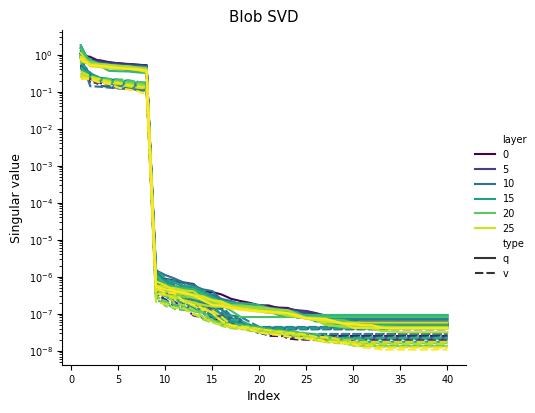

In [44]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Prepare Blob Dataframe
names = []
singulars = []
types = []
layers = []

for name, s in blob_singulars.items():
    if s.shape[0] > 0:
        names.append(name)
        singulars.append(s[:40])
        # Naming convention: layers.0.self_attn.q_proj
        types.append("v" if "v_proj" in name else "q" if "q_proj" in name else "k" if "k_proj" in name else "o" if "o_proj" in name else "other")
        # Extract layer number
        parts = name.split('.')
        layer_num = -1
        for p in parts:
            if p.isdigit():
                layer_num = p
                break
        layers.append(layer_num)

df_blob = pd.DataFrame({"name": names, "singular_values": singulars, "type": types, "layer": layers})
df_blob['Method'] = "Blob"
df_blob['layer'] = df_blob['layer'].apply(lambda x: int(x) if str(x).isdigit() else -1)

# Process for plotting
df_blob_plot = df_blob[df_blob['type'].isin(['q', 'v'])]
df_blob_plot = df_blob_plot.explode("singular_values", ignore_index=True)
df_blob_plot["singular_values"] = df_blob_plot["singular_values"].astype(float)
df_blob_plot["sv_idx"] = df_blob_plot.groupby(["Method", "name"]).cumcount() + 1

# Plot Blob
g = sns.relplot(
    data=df_blob_plot,
    kind="line",
    x="sv_idx",
    y="singular_values",
    hue="layer",
    style="type",
    height=4,
    aspect=1.2,
    palette="viridis",
)
g.set(yscale="log")
g.set_axis_labels("Index", "Singular value")
plt.title("Blob SVD")
# plt.ylim(1e-4, 2e-2)
# plt.xlim(8, 40)
plt.show()

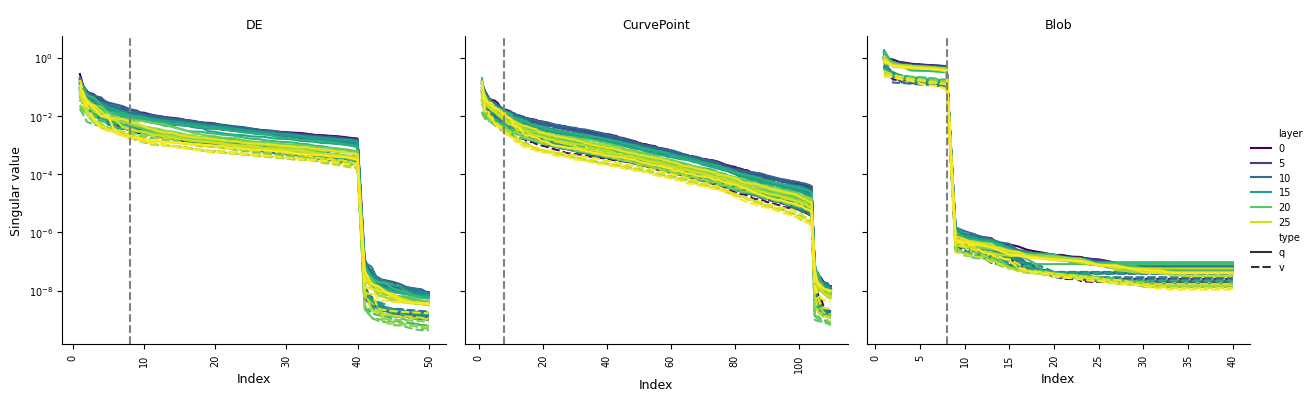

In [50]:
# Assuming df and df_curve_point exist from previous cells
# Ensure consistent processing of df, df_curve_point, and df_blob

# Recalculate if needed for consistency
# df from DE cell
# df_curve_point from Curve cell

# 1. Standardize Blob
df_blob_formatted = df_blob.copy()
df_blob_formatted = df_blob_formatted[df_blob_formatted['type'].isin(['q', 'v'])]
df_blob_formatted = df_blob_formatted.explode("singular_values", ignore_index=True)
df_blob_formatted["singular_values"] = df_blob_formatted["singular_values"].astype(float)
df_blob_formatted["sv_idx"] = df_blob_formatted.groupby(["Method", "name"]).cumcount() + 1

# 2. Standardize DE and Curve (assumes df and df_curve_point are present and unprocessed or semi-processed)
# Re-create df and df_curve_point formatting if needed to ensure columns match
# Re-using logic from the DE/Curve cell but making it robust

# Combine everything
df_all = pd.concat([df_cmp, df_blob_formatted], ignore_index=True)
df_all["singular_values"] = df_all["singular_values"].astype(float)

g = sns.relplot(
    data=df_all,
    kind="line",
    x="sv_idx",
    y="singular_values",
    hue="layer",
    style="type",
    col="Method",
    col_order=["DE", "CurvePoint", "Blob"],
    height=4,
    aspect=1.0,
    palette="viridis",
    facet_kws={'sharex': False},
)

g.set_axis_labels("Index", "Singular value")
g.set_titles("{col_name}")

for ax in g.axes.flat:
    ax.set_yscale("log")
    ax.tick_params(axis="x", rotation=90)
    # ax.set_ylim(1e-4, 2e-2)
    # ax.set_xlim(0, 40)
    ax.axvline(x=8, color='gray', linestyle='--', label='8th singular value')

g.add_legend(loc='upper left', bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()

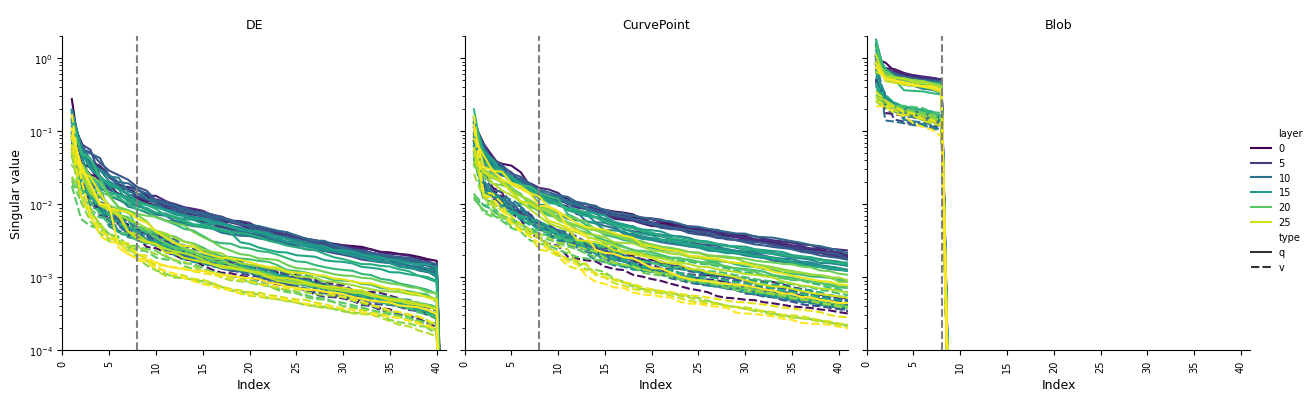

In [49]:
g = sns.relplot(
    data=df_all,
    kind="line",
    x="sv_idx",
    y="singular_values",
    hue="layer",
    style="type",
    col="Method",
    col_order=["DE", "CurvePoint", "Blob"],
    height=4,
    aspect=1.0,
    palette="viridis",
    facet_kws={'sharex': False},
)

g.set_axis_labels("Index", "Singular value")
g.set_titles("{col_name}")

for ax in g.axes.flat:
    ax.set_yscale("log")
    ax.tick_params(axis="x", rotation=90)
    ax.set_ylim(1e-4, 2.)
    ax.set_xlim(0, 41)
    ax.axvline(x=8, color='gray', linestyle='--', label='8th singular value')

g.add_legend(loc='upper left', bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()

In [51]:
blob_rang = df_blob['singular_values'].apply(lambda x: np.sum(x > 1e-5)).to_numpy()
blob_rang

array([8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8,
       8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8,
       8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 2])

Text(0, 0.5, 'Count (log scale)')

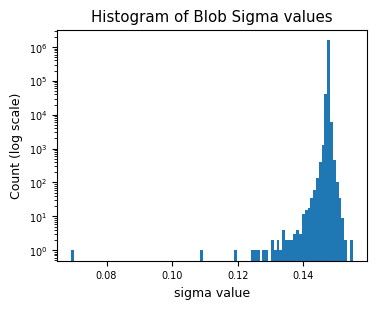

In [57]:
# analyse blib sigma
blob_sigmas = np.load("../BayesAdapt/blob_wino_m_s1_sigmas.npy")
plt.figure(figsize=(4, 3))
plt.hist(blob_sigmas.flatten(), bins=100)
plt.yscale("log")
plt.xlabel("sigma value")
plt.title("Histogram of Blob Sigma values")
plt.ylabel("Count (log scale)")

### test arc-challenge test metric diff DE(5)

In [7]:
import wandb
run = wandb.Api().run("ddold/qwen_PtoC_seg/ebv2pnli")  # ARC-Challenge
config, data, rng_key = load_config_and_data(run)
env, params, rng_key = _setup_training_env(config, data, rng_key)
env

Dataset loaded: 1100 samples, 5 classes
Target token IDs: [[32]
 [33]
 [34]
 [35]
 [36]]
Validation data are used
Training data: 988 samples, Validation data: 112 samples
Control point fixed list: [1, 0, 0, 1, 0, 0, 1, 0, 0, 1, 0, 0, 1]
Setting num_epochs to 41 to match 10000 steps
Setting num_steps to 10127 to match 41 epochs


Using cosine rho schedule with total steps 10127
save best parameters


TrainingEnv(s_model=<src.subspace_curve.LoRACategorySubspace object at 0x7f9f7437d360>, optimizer=GradientTransformationExtraArgs(init=<function chain.<locals>.init_fn at 0x7f9f742036d0>, update=<function chain.<locals>.update_fn at 0x7f9f742035b0>), t_sample_fn=<function _setup_t_sample_fn.<locals>.t_sample_fn_v2 at 0x7f9f74357010>, rho_scheduler=<function _setup_rho_scheduler.<locals>.rho_scheduler at 0x7f9f74312b90>, valid_metrics_fn=<function _setup_validation.<locals>.valid_metrics_fn at 0x7f9f74201e10>, empty_metric=({'val_mean_loss': Array(inf, dtype=float32), 'val_mean_acc': Array(-inf, dtype=float32), 'val_mean_ece': Array(inf, dtype=float32), 'val_bma_ll': Array(-inf, dtype=float32), 'val_bma_acc': Array(-inf, dtype=float32), 'val_bma_ece': Array(inf, dtype=float32)}, None), get_best_params=<function _setup_validation.<locals>.get_best_params at 0x7f9f74201ea0>, train_step=<PjitFunction of <function _setup_training_env.<locals>._scan_jit at 0x7f9f74203a30>>)